# Лекция 10. Многомерное интегрирование и стохастические методы

В предыдущей лекции мы научились вычислять одномерные интегралы
квадратурными формулами. Вся практическая механика того разбора
переносится на многомерный случай, но появляется новое качество задач:
с ростом числа переменных $d$ цена любой сеточной кубатуры растёт
экспоненциально - это называют **проклятием размерности** (curse of
dimensionality), а спасает от него **метод Монте-Карло** (Monte Carlo) —
стохастическая оценка, у которой погрешность падает как $N^{-1/2}$
независимо от $d$.



## 1. 🧮 Кубатурные формулы: тензорное произведение одномерных правил

📖 **Определение.** **Кубатурной формулой** (многомерной квадратурной формулой) называется приближённое равенство:

$$
I := \int_{\Omega} f(x)\,dx \:\approx\: \sum_{j=0}^{n} A_j\, f(x_j), \qquad \Omega \subset \mathbb{R}^d,
$$

где:
* $x_j \in \Omega$ — узлы,
* $A_j$ — веса,
* погрешность — остаточный член.

*Примечание:* Всё, что мы знали об узлах, весах и остаточном члене в лекции 9, работает здесь дословно (при $d = 1$ кубатурная формула — просто квадратурная).

---

### Тензорное произведение одномерных методов

Самая важная конструкция — **тензорное произведение одномерных методов**. 

Разобьём куб $[0,1]^d$ на клетки с шагом $h$ по каждой оси. На каждой клетке применяем одномерное правило с узлами и весами $(\xi_s, w_s)$, где $s = 0..n$, а результаты перемножаются по осям:

$$
I \approx T_d(h) = \sum_{s_1=0}^{n}\cdots\sum_{s_d=0}^{n} w_{s_1}\cdots w_{s_d}\, f(\xi_{s_1}, \dots, \xi_{s_d})
$$

То есть мы суммируем по всем узлам полной $d$-мерной сетки. 

* **Число узлов:** $N = (n + 1)^d \approx n^d$
* **Главный вывод:** цена сеточной кубатуры растёт **экспоненциально по числу переменных** (проклятие размерности).

---

### Остаточный член и гладкость

Остаточный член в тензорной конструкции складывается по осям:

* **Для правила средней точки:** локальная ошибка клетки (формула Тейлора из лекции 9) равна $r_{\text{лок}} = \tfrac{h^3}{24} f''(\tilde\xi)$. По каждой из $d$ осей такие члены интегрируются остальными переменными, и после суммирования по всем осям получаем оценку:

$$
|r_T| \le \frac{d\,M_2\,\,h^2}{24}, \qquad h = \frac{1}{n},
$$

где $M_2 = \max_k \bigl|\partial^2 f/\partial x_k^2\bigr|$.

* **Для правила порядка $p$:** тот же механизм даёт $|r_T| = O(h^p)$ с коэффициентом, растущим примерно пропорционально $d$.

#### Важные нюансы:
* **Требование гладкости** переносится дословно: для правила порядка $p$ нужны непрерывные частные производные до порядка $p$ включительно.
* **Проблемные места** (изломы, нерегулярность) — та же история, что в лекции 9: порядковая скорость теряется.

---

🔬 **Численная проверка:** проверяем численно на тензорном правиле **Симпсона** (порядок $p = 4$, $|r_T| = O(h^4) = O(N^{-4/d})$).


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
plt.rcParams['figure.dpi'] = 110

rng = np.random.default_rng(7)          # генератор случайных чисел

# сквозной пример: I_d = I0^d, f(x) = exp(-|x|^2) на кубе [0,1]^d
f0 = lambda t: np.exp(-t ** 2)
I0 = math.sqrt(math.pi) / 2 * math.erf(1.0)
J1 = math.sqrt(math.pi / 8) * math.erf(math.sqrt(2))   # ∫₀¹ e^(-2x²) dx
I_of_d = lambda d: I0 ** d
M2 = 2.0                                # max |d²f/dx_k²| = 2 по каждой оси
print(f'сквозной пример: I_d = I0^d,  I0 = {I0:.15f},  J1 = {J1:.9f}')
for d in [1, 2, 4, 6, 10, 20]:
    print(f'  d={d:2d}: I_d = I0^d = {I_of_d(d):.9f}')

сквозной пример: I_d = I0^d,  I0 = 0.746824132812427,  J1 = 0.598144007
  d= 1: I_d = I0^d = 0.746824133
  d= 2: I_d = I0^d = 0.557746285
  d= 4: I_d = I0^d = 0.311080919
  d= 6: I_d = I0^d = 0.173504227
  d=10: I_d = I0^d = 0.053973854
  d=20: I_d = I0^d = 0.002913177


тензорное правило Симпсона, сквозной пример I_d:
   n |  узлов (d=2)   |I−T| d=2 |  узлов (d=4)   |I−T| d=4
   4 |           25    4.67e-05 |          625    5.21e-05
   8 |           81    2.97e-06 |         6561    3.31e-06
  16 |          289    1.86e-07 |        83521    2.08e-07
  32 |         1089    1.16e-08 |      1185921    1.30e-08
порядок ошибки O(h^4) сохраняется при росте d (коэффициент типично ~ d)


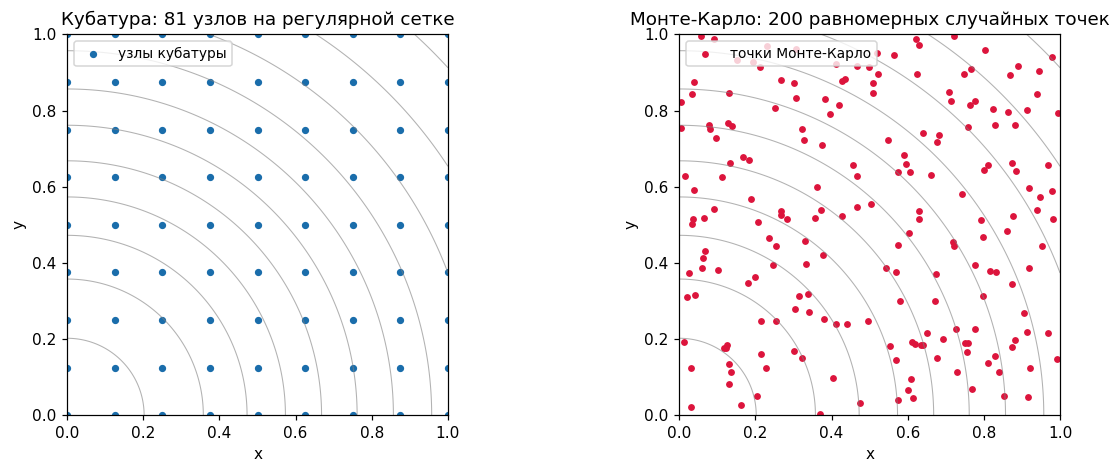

In [2]:
def simpson_weights(n):
    # веса правила Симпсона на n отрезках (n+1 узлов), шаг h = 1/n
    h = 1 / n
    w = np.ones(n + 1)
    w[1::2] = 4
    w[2:-1:2] = 2
    return w * h / 3

def tensor_simpson_separ(d, n):
    # тензорный Симпсон для сепарабельной f: (w·f(x_s))^d — по осям одинаково
    xs = np.linspace(0, 1, n + 1)
    return (simpson_weights(n) @ f0(xs)) ** d

print('тензорное правило Симпсона, сквозной пример I_d:')
print(f"{'n':>4} | {'узлов (d=2)':>12} {'|I−T| d=2':>11} | "
      f"{'узлов (d=4)':>12} {'|I−T| d=4':>11}")
for n in [4, 8, 16, 32]:
    e2 = abs(tensor_simpson_separ(2, n) - I_of_d(2))
    e4 = abs(tensor_simpson_separ(4, n) - I_of_d(4))
    print(f'{n:4d} | {(n + 1) ** 2:12d} {e2:11.2e} | '
          f'{(n + 1) ** 4:12d} {e4:11.2e}')
print('порядок ошибки O(h^4) сохраняется при росте d (коэффициент типично ~ d)')

# 2D-картина: сетка кубатуры против случайных точек Монте-Карло
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
n_grid = 8
gs = np.linspace(0, 1, n_grid + 1)
GX, GY = np.meshgrid(gs, gs)
ts = np.linspace(0, 1, 300)
T, Q = np.meshgrid(ts, ts)
Z = np.exp(-(T ** 2 + Q ** 2))
for ax in axes:
    ax.contour(T, Q, Z, levels=10, colors='gray',
               linewidths=0.7, alpha=0.6)
    ax.set_xlabel('x'); ax.set_ylabel('y')
    ax.set_aspect('equal')
axes[0].scatter(GX.ravel(), GY.ravel(), s=14, c='#1a6dab',
                label='узлы кубатуры')
axes[0].set_title(f'Кубатура: {(n_grid + 1) ** 2} узлов на регулярной сетке')
mc = rng.random((200, 2))
axes[1].scatter(mc[:, 0], mc[:, 1], s=12, c='crimson',
                label='точки Монте-Карло')
axes[1].set_title('Монте-Карло: 200 равномерных случайных точек')
axes[0].legend(loc='upper left', fontsize=9)
axes[1].legend(loc='upper left', fontsize=9)
plt.tight_layout(); plt.show()


## 2. 🧟 Проклятие размерности: почему сеточные методы сдаются

Рассмотрим тензорное правило порядка $p$ на многомерном кубе $[0, 1]^d$. Сюда относятся:
* **Правило средней точки и трапеций:** $p = 2$
* **Правило Симпсона:** $p = 4$
* **Гауссовы квадратуры:** любые высокие порядки $p$

Ошибка такого метода составляет $O(h^p)$, где $h$ — шаг сетки по каждой из $d$ осей. Общее число узлов при этом равно $N \approx h^{-d}$. Подставляя шаг $h = N^{-1/d}$ в оценку погрешности, мы получаем **главное соотношение размерности**:

$$
|r_T| = O\bigl(N^{-p/d}\bigr)
$$

---

### Анализ эффективности при росте размерности

Пока размерность $d$ мала, метод работает превосходно. Однако с увеличением $d$ показатель степени $p/d$ стремительно тает. 

#### 📊 Эффект масштабирования сетки (сравнение при $d=1$ и $d=10$):
* **При $d = 1$ (одномерный случай):** десятикратный рост числа узлов ($N \to 10N$) уменьшает ошибку в $10^4 = 10\,000$ раз.
* **При $d = 10$ (десятимерный случай):** тот же десятикратный рост числа узлов для правила Симпсона ($p = 4$) уменьшает ошибку всего в $10^{4/10} \approx 2.5$ раза.

Чтобы достичь заданной точности $\varepsilon$, алгоритму потребуется вычислить функцию $f$ следующее количество раз:

$$
N \sim C \cdot \varepsilon^{-d/p}
$$

Это **экспоненциальный рост сложности по $d$**. Именно данное явление Ричард Беллман в 1957 году назвал **проклятием размерности** (*curse of dimensionality*).

---

### ⚔️ Противостояние: Сеточные методы vs Монте-Карло

Погрешность метода Монте-Карло составляет $O(N^{-1/2})$ и **вообще не зависит от размерности $d$**. 

Сеточные методы начинают проигрывать случайному поиску в тот момент, когда показатель степени их сходимости падает ниже показателя Монте-Карло, то есть при $p/d < 1/2$. Отсюда легко находится **критический порог размерности**:

$$
d > 2p
$$

#### Точки перехода для популярных методов:
* **Для правил 2-го порядка** (средние точки, трапеции): порог наступает при $d > 4$.
* **Для правила Симпсона** ($p = 4$): порог наступает при $d > 8$.

Как только размерность задачи превышает этот предел, сеточные методы окончательно сдаются, и метод Монте-Карло становится единственным разумным выбором.


бюджет точности ε = 1e-3: сеточное правило средней точки vs Монте-Карло
  d | n_d по оси |   узлов n_d^d |  sigma_d  N Монте-Карло
  1 |         10 |      1.00e+01 |   0.2010         155192
  2 |         13 |      1.69e+02 |   0.2161         179385
  4 |         19 |      1.30e+05 |   0.1767         119983
  6 |         23 |      1.48e+08 |   0.1253          60286
  8 |         26 |      2.09e+11 |   0.0838          26969
 10 |         29 |      4.21e+14 |   0.0543          11329
 16 |         37 |      1.23e+25 |   0.0134            694
 20 |         41 |      1.80e+32 |   0.0051             99


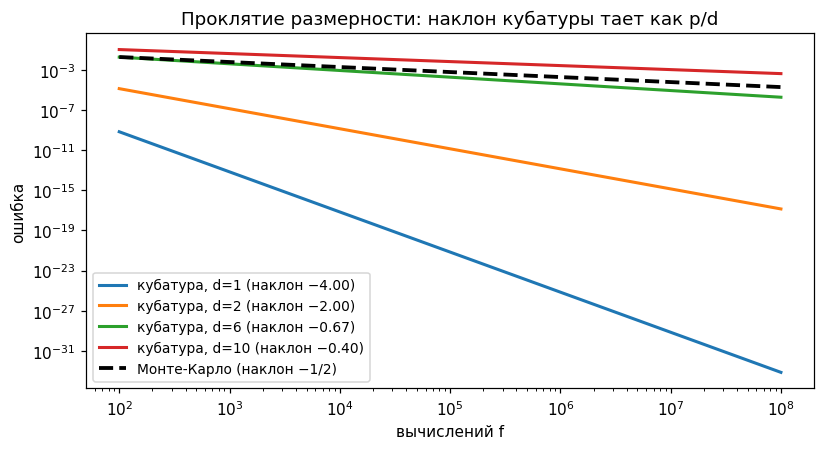

In [7]:
var_of_d = lambda d: max(J1 ** d - I_of_d(d) ** 2, 0.0)

eps = 1e-3
print(f'бюджет точности ε = 1e-3: сеточное правило средней точки vs Монте-Карло')
print(f"{'d':>3} | {'n_d по оси':>10} | {'узлов n_d^d':>13} | "
      f"{'sigma_d':>8} {'N Монте-Карло':>14}")
for d in [1, 2, 4, 6, 8, 10, 16, 20]:
    nd = math.ceil(math.sqrt(d * M2 / (24 * eps)))
    sig = math.sqrt(var_of_d(d))
    Nmc = (1.96 * sig / eps) ** 2
    print(f'{d:3d} | {nd:10d} | {nd ** d:13.2e} | {sig:8.4f} {Nmc:14.0f}')

# график: наклон ошибки кубатуры (−p/d) против Монте-Карло (−1/2)
fig, ax = plt.subplots(figsize=(7.6, 4.2))
nodes_log = np.logspace(2, 8, 80)
p = 4                                   # Симпсон
for d in [1, 2, 6, 10]:
    err_cub = 0.07 * d * nodes_log ** (-p / d)   # C_d ≈ (M4/180)·d на сегм.
    ax.loglog(nodes_log, err_cub, lw=2,
              label=f'кубатура, d={d} (наклон −{p / d:.2f})')
err_mc = 0.2 * nodes_log ** -0.5        # 1.96·sigma_d/√N, sigma_d ≈ 0.2
ax.loglog(nodes_log, err_mc, 'k--', lw=2.5, label='Монте-Карло (наклон −1/2)')
ax.set_xlabel('вычислений f')
ax.set_ylabel('ошибка')
ax.legend(fontsize=9)
ax.set_title('Проклятие размерности: наклон кубатуры тает как p/d')
plt.tight_layout(); plt.show()


## 3. 🎲 Метод Монте-Карло

**Идея.** Превратим интеграл в математическое ожидание. Если $X$ —
случайная точка, равномерно распределённая на $\Omega$, то

$$
I = \int_\Omega f(x)\,dx = |\Omega|\;\mathbb{E}\,f(X)
$$

(доказательство: для равномерного закона плотность равна
$1/|\Omega|$, поэтому
$\mathbb{E}\,f(X) = \int_\Omega f(x)\,\frac{dx}{|\Omega|}$, и объём
$|\Omega|$ выходит наружу). Дальше оцениваем математическое ожидание
стохастически: выбираем $N$ независимых точек $X_1, \dots, X_N$ и
строим **выборочное среднее**

$$
I_N := \frac{|\Omega|}{N}\sum_{j=1}^{N} f(X_j).
$$

У этой оценки четыре столпа — приводим их полностью.

1. **Несмещённость.** Математическое ожидание линейно, а точки
   распределены одинаково:

$$
\mathbb{E}\,I_N = \frac{|\Omega|}{N}\sum_{j=1}^{N}\mathbb{E}\,f(X_j)
= |\Omega|\,\mathbb{E}\,f(X) = I .
$$

2. **Дисперсия оценки** (независимость точек, $\mathrm{Var}\,f =
   \sigma^2$):

$$
\mathrm{Var}\,I_N = \frac{|\Omega|^2}{N^2}\sum_{j=1}^{N}
\mathrm{Var}\,f(X_j) = \frac{|\Omega|^2\,\sigma^2}{N}.
$$

3. **Закон больших чисел.** Неравенство Чебышёва
   ($P(|Y-\mathbb{E}Y| \ge \varepsilon) \le \mathrm{Var}\,Y/\varepsilon^2$,
   которое следует из неравенства Маркова
   $P(|Y|\ge t)\le \mathbb{E}Y^2/t^2$, применённого к $Y = I_N - I$) даёт

$$
P\bigl(|I_N - I| \ge \varepsilon\bigr) \le
\frac{|\Omega|^2\sigma^2}{N\,\varepsilon^2} \xrightarrow[N\to\infty]{} 0 .
$$

4. **Центральная предельная теорема.** При больших $N$ случайная
   величина $\sqrt{N}\,(I_N - I)/(|\Omega|\,\sigma)$ распределена
   примерно как $\mathcal{N}(0, 1)$, откуда рабочая оценка погрешности:

$$
|I_N - I| \approx \frac{1.96\,|\Omega|\,\sigma}{\sqrt{N}}
\quad \text{с вероятностью 95\%}.
$$

Точность «по построению» — $\sigma/\sqrt N$: десятикратный рост $N$
уменьшает погрешность лишь в $\sqrt{10} \approx 3.2$ раза, зато запись
$N^{-1/2}$ **не содержит $d$** — размерность исчезла из сходимости.

Стандартное отклонение $\sigma$ заранее неизвестно, но оно оценивается
по той же выборке (**выборочное стандартное отклонение** $\hat\sigma$),
поэтому всё практическое оценивание работает «на месте».
Проверяем оба факта на сквозном примере ($|\Omega| = 1$).


        N |           I_N    |I_N−I|  1.96·s/√N |  фактор
     1000 |   0.750090533   3.27e-03   1.24e-02 |       —
    10000 |   0.745153845   1.67e-03   3.97e-03 |    ×2.0
   100000 |   0.746846466   2.23e-05   1.24e-03 |   ×74.8
  1000000 |   0.746932506   1.08e-04   3.94e-04 |    ×0.2
ошибка падает как 1/√N: ×10 узлов → ×3.2 точности


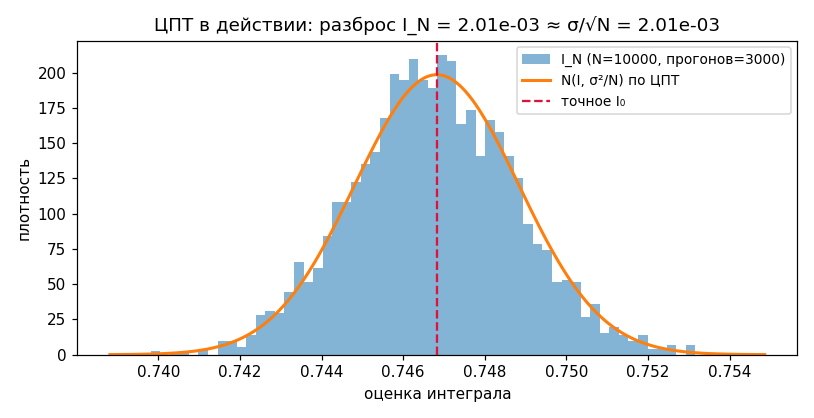

In [ ]:
print(f"{'N':>9} | {'I_N':>13} {'|I_N−I|':>10} {'1.96·s/√N':>10} | {'фактор':>7}")
prev_err = None
for N in [1000, 10000, 100000, 1000000]:
    x = rng.random(N)
    fx = np.exp(-x * x)
    est = fx.mean()
    sd = fx.std(ddof=1)
    err = abs(est - I0)
    factor = '—' if prev_err is None else f'×{prev_err / err:.1f}'
    print(f'{N:9d} | {est:13.9f} {err:10.2e} '
          f'{1.96 * sd / math.sqrt(N):10.2e} | {factor:>7}')
    prev_err = err
print('ошибка падает как 1/√N: ×10 узлов → ×3.2 точности')

# ЦПТ: распределение I_N по повторным прогонам — гауссова плотность
N, reps = 10000, 3000
ests = np.array([np.exp(-rng.random(N) ** 2).mean() for _ in range(reps)])
sigma1 = math.sqrt(J1 - I0 ** 2)        # σ² = ∫e^(-2x²) dx − I0²
fig, ax = plt.subplots(figsize=(7.4, 3.8))
ax.hist(ests, bins=60, density=True, alpha=0.55,
        label=f'I_N (N={N}, прогонов={reps})')
ts = np.linspace(ests.min() - 1e-3, ests.max() + 1e-3, 400)
dens = np.exp(-(ts - I0) ** 2 / (2 * sigma1 ** 2 / N)) /     math.sqrt(2 * math.pi * sigma1 ** 2 / N)
ax.plot(ts, dens, lw=2, label='N(I, σ²/N) по ЦПТ')
ax.axvline(I0, color='crimson', ls='--', lw=1.5, label='точное I₀')
ax.set_xlabel('оценка интеграла'); ax.set_ylabel('плотность')
ax.legend(fontsize=9)
ax.set_title(f'ЦПТ в действии: разброс I_N = {ests.std(ddof=1):.2e} '
             f'≈ σ/√N = {sigma1 / math.sqrt(N):.2e}')
plt.tight_layout(); plt.show()


## 4. 📊 Вероятностный анализ и статистика: доверительные интервалы, последовательное удвоение, вероятности шара

Статистическая теория добавляет к методу Монте-Карло три важнейших практических инструмента.

---

### 1. Выборочная оценка дисперсии и доверительный интервал

На практике истинная дисперсия $\sigma^2$ неизвестна. Мы оцениваем её непосредственно по той же рабочей выборке, используя несмещённую оценку:

$$
\hat{\sigma}^2 = \frac{1}{N-1}\sum_{j=1}^{N} \bigl(f(X_j) - \overline{f}\bigr)^2, \qquad \text{где } \overline{f} = \frac{1}{N} \sum_{j=1}^{N} f(X_j)
$$

Согласно Центральной предельной теореме, при больших $N$ погрешность приближения задаётся **доверительным интервалом** для заданного уровня надёжности (например, 95%):

$$
I \in \left[ \overline{f} - 1.96\frac{\hat{\sigma}}{\sqrt{N}}, \ \overline{f} + 1.96\frac{\hat{\sigma}}{\sqrt{N}} \right]
$$

*   Коэффициент $1.96$ — это квантиль стандартного нормального распределения, отвечающий двусторонней вероятности 95%.
*   При достаточно больших $N$ замена истинной дисперсии $\sigma^2$ на её оценку $\hat{\sigma}^2$ практически не вносит дополнительных погрешностей.

---

### 2. Алгоритм последовательного удвоения $N$

Этот алгоритм реализует адаптивный подбор числа испытаний. Принцип аналогичен правилу Рунге из лекции 9, но здесь оценка погрешности вычисляется автоматически через выборочную дисперсию:

1.  Задаём начальное (небольшое) число точек $N$ и требуемую точность $\varepsilon$.
2.  Вычисляем интеграл и текущую погрешность $\Delta = \frac{1.96\,\hat{\sigma}}{\sqrt{N}}$.
3.  Повторяем цикл **удвоения выборки** ($N \leftarrow 2N$) до тех пор, пока выполняется условие:

$$
\frac{1.96\,\hat{\sigma}}{\sqrt{N}} > \varepsilon
$$

**Выход из цикла** происходит в момент достижения заданной точности:

$$
\frac{1.96\,\hat{\sigma}}{\sqrt{N}} \le \varepsilon
$$

*   **Оптимизация:** Каждая новая итерация требует генерации всего $\frac{N}{2}$ новых случайных точек и вычислений функции $f$ от них. Все накопленные на предыдущих шагах значения полностью переиспользуются.

---

### 3. Интегралы по плотностям — математические ожидания

Вычисление интегралов по вероятностной мере — классическая задача математической статистики. Нам часто требуется найти математическое ожидание функции или вероятность попадания случайной величины в область $B$:

$$
\mathbb{E}\,g(X) = \int_{\mathbb{R}^d} g(x)\,p(x)\,dx, \qquad P(X \in B) = \int_B p(x)\,dx
$$

Метод Монте-Карло позволяет решать обе задачи единообразно. Если мы моделируем случайные векторы $X_j$ из распределения с плотностью $p(x)$, то выборочное среднее $\frac{1}{N}\sum g(X_j)$ служит несмещённой оценкой для $\mathbb{E}\,g(X)$ (доказательство аналогично §3).

---

### 🎯 Модельная задача: Вероятность попадания в многомерный шар

Пусть $X$ — стандартный $d$-мерный нормальный случайный вектор ($X \sim \mathcal{N}(0, I_d)$). Нам нужно найти вероятность его попадания в шар радиуса $r$:

$$
P_{d,r} = P(\|X\| \le r) = \int_{\|x\| \le r} \frac{e^{-\|x\|^2/2}}{(2\pi)^{d/2}}\,dx
$$

#### Аналитическое решение:
Известно, что сумма квадратов независимых стандартных нормальных величин $\|X\|^2$ распределена по закону Хи-квадрат с $d$ степенями свободы ($\chi^2_d$). Поэтому при $t = \frac{r^2}{2}$ искомая вероятность строго выражается через **неполную гамма-функцию**:

$$
P_{d,r} = \frac{\gamma\left(\tfrac{d}{2}, \ t\right)}{\Gamma\left(\tfrac{d}{2}\right)}
$$

Где неполная гамма-функция раскладывается в абсолютно сходящийся ряд:
$$
\gamma(s, t) = \int_0^t u^{s-1} e^{-u}\,du = t^s e^{-t} \sum_{k=0}^{\infty} \frac{t^k}{s(s+1)\cdots(s+k)}
$$

*   **Важный частный случай ($d = 2$):** Распределение $\chi^2_2$ совпадает с экспоненциальным распределением с параметром масштаба $1/2$. Формула упрощается до красивого аналитического вида:
$$
P_{2,r} = 1 - e^{-r^2/2}
$$

*   **Численный эксперимент:** Ниже мы вычислим точные значения через этот ряд для конкретного радиуса $r = 1$ и сравним их с результатами прямого моделирования Монте-Карло при фиксированном $N$.

---

### ⚠️ Эффект редких событий (Важное ограничение)

При больших размерностях $d$ и малых радиусах $r$ геометрический объём шара стремительно сжимается, и вероятность $P_{d,r}$ становится исчезающе малой.

> **Пример:** Для размерности $d=10$ и радиуса $r=0.5$ вероятность составляет $P_{10,0.5} \sim 10^{-8}$.

Чтобы стандартный метод Монте-Карло «в лоб» зафиксировал хотя бы несколько попаданий в эту область, потребуется сгенерировать нереальное число точек:

$$
N \sim \frac{1}{P} \approx 10^8 \text{ и более}
$$

Прямое моделирование здесь полностью отказывает. Эффективный выход из этого тупика — использование метода выборки по значимости (*importance sampling*), который мы подробно разберём в **§5**, и других специализированных квадратур редких событий.


In [6]:
import math
import numpy as np

# Инициализируем генератор случайных чисел (современное API NumPy)
rng = np.random.default_rng(seed=42)

def gamma_lower(s, t):
    """
    Вычисляет нижнюю неполную гамма-функцию γ(s, t) через разложение в ряд:
    γ(s, t) = t^s * e^(-t) * Σ [ t^k / (s * (s+1) * ... * (s+k)) ]
    Ряд абсолютно сходится при любых положительных s и t.
    """
    total = 0.0
    term = 1.0 / s  # Первый член ряда (при k = 0)
    k = 0
    
    while True:
        total += term
        # Условие остановки: очередной член ряда стал ничтожно мал по сравнению с накопленной суммой
        if abs(term) < 1e-16 * (abs(total) + 1e-300):
            break
        
        # Рекуррентное вычисление следующего члена ряда
        term *= t / (s + k + 1)
        k += 1
        
        # Защита от бесконечного цикла
        if k > 5000:
            break
            
    return (t ** s) * math.exp(-t) * total

def ball_prob_exact(d, r):
    """
    Точное аналитическое вычисление вероятности попадания стандартного 
    нормального d-мерного вектора в шар радиуса r через Гамма-распределение.
    """
    t = (r * r) / 2.0
    return gamma_lower(d / 2.0, t) / math.gamma(d / 2.0)

def ball_prob_mc(d, r, N):
    """
    Численная оценка вероятности методом Монте-Карло.
    Возвращает: (выборочное среднее, выборочное стандартное отклонение)
    """
    # Генерируем матрицу N случайных d-мерных нормальных векторов
    xs = rng.standard_normal((N, d))
    
    # Проверяем условие попадания в шар: сумма квадратов координат <= r^2
    inside = ((xs ** 2).sum(axis=1) <= r ** 2)
    
    # Возвращаем оценку вероятности (долю попаданий) и несмещенное стандартное отклонение
    return inside.mean(), inside.std(ddof=1)

# =====================================================================
# ЧАСТЬ 1. Сравнение точного решения и прямого метода Монте-Карло
# =====================================================================
r = 1.0
N_mc = 2_000_000

print(f"=== Вероятность попадания в шар радиуса r = {r} ===")
print(f"{'d':>3} | {'Точное (ряд)':>15} | {'MC (N=2e6)':>11} | {'Ошибка':>9} | {'Дов. интервал':>13}")
print("-" * 65)

for d in [2, 4, 6, 8, 10]:
    p_exact = ball_prob_exact(d, r)
    p_mc, sd = ball_prob_mc(d, r, N_mc)
    
    # Вычисляем радиус доверительного интервала (уровень доверия 95%, квантиль 1.96)
    conf_interval = 1.96 * sd / math.sqrt(N_mc)
    error = abs(p_mc - p_exact)
    
    print(f"{d:3d} | {p_exact:15.9f} | {p_mc:11.6f} | {error:9.2e} | {conf_interval:13.2e}")

# Аналитическая проверка формулы для d = 2
p_analytic_d2 = 1.0 - math.exp(- (r**2) / 2.0)
print(f"\nПроверка при d = 2: 1 - e^(-r²/2) = {p_analytic_d2:.9f} (совпадает с рядом)\n")


# =====================================================================
# ЧАСТЬ 2. Алгоритм последовательного честного удвоения выборки N
# =====================================================================
eps = 1e-3  # Требуемая точность (максимальный статистический шум)
d = 4       # Размерность пространства

print(f"=== Послеводательное удвоение N (d = {d}, r = {r}, ε = {eps:.0e}) ===")
print(f"{'Размер N':>9} | {'Текущая ошибка':>15} | {'Требуемая ε':>11}")
print("-" * 43)

# Начинаем со стартовой базовой выборки (N = 512)
fvals = ((rng.standard_normal((512, d)) ** 2).sum(axis=1) <= r ** 2)
p_exact_d4 = ball_prob_exact(d, r)

while True:
    est = fvals.mean()
    sd = fvals.std(ddof=1)
    
    # Оценка стандартной ошибки (статистического шума) текущей выборки
    stderr = 1.96 * sd / math.sqrt(fvals.size)
    
    print(f"{fvals.size:9d} | {stderr:15.2e} | {eps:11.0e}")
    
    # Критерий остановки: если статистическая погрешность меньше ε, выходим из цикла
    if stderr <= eps:
        break
        
    # Честное удвоение выборки: генерируем ровно столько же новых данных, сколько уже накоплено
    new_points = ((rng.standard_normal((fvals.size, d)) ** 2).sum(axis=1) <= r ** 2)
    
    # Объединяем старые результаты с новыми (переиспользование накопленных вычислений)
    fvals = np.concatenate([fvals, new_points])

print("-" * 43)
print(f"Остановка на N = {fvals.size} вычислений функции.")
print(f"Фактическая ошибка: {abs(fvals.mean() - p_exact_d4):.2e} <= заданного порога ε (Доверие 95%)")
print("Каждое удвоение генерирует ровно N новых значений, полностью сохраняя старые.")


=== Вероятность попадания в шар радиуса r = 1.0 ===
  d |    Точное (ряд) |  MC (N=2e6) |    Ошибка | Дов. интервал
-----------------------------------------------------------------
  2 |     0.393469340 |    0.393730 |  2.60e-04 |      6.77e-04
  4 |     0.090204010 |    0.090479 |  2.74e-04 |      3.98e-04
  6 |     0.014387678 |    0.014476 |  8.78e-05 |      1.66e-04
  8 |     0.001751623 |    0.001762 |  1.04e-05 |      5.81e-05
 10 |     0.000172116 |    0.000182 |  1.04e-05 |      1.87e-05

Проверка при d = 2: 1 - e^(-r²/2) = 0.393469340 (совпадает с рядом)

=== Послеводательное удвоение N (d = 4, r = 1.0, ε = 1e-03) ===
 Размер N |  Текущая ошибка | Требуемая ε
-------------------------------------------
      512 |        2.22e-02 |       1e-03
     1024 |        1.65e-02 |       1e-03
     2048 |        1.22e-02 |       1e-03
     4096 |        8.69e-03 |       1e-03
     8192 |        6.15e-03 |       1e-03
    16384 |        4.41e-03 |       1e-03
    32768 |        3.15e-0

## 5. Снижение дисперсии: Antithetic, Control Variates, Importance Sampling

**Погрешность метода Монте-Карло уменьшается пропорционально $\frac{\sigma}{\sqrt{N}}$**. 
Чтобы повысить точность вычислений, необходимо снижать стандартное отклонение ($\sigma$) без потери несмещённости оценки. Ниже подробно разобраны три классических приёма снижения дисперсии на примере вычисления интеграла:

$$I_0 = \int_0^1 e^{-x^2}dx$$

---

### А. Antithetic Variates (Антитетические / сопряжённые переменные)

Метод использует пары зависимых случайных величин с отрицательной корреляцией. Если функция $f(x)$ монотонна, случайные точки генерируют парами: $u$ и $1-u$, где $u \sim U(0, 1)$.

*   **Формула оценки по паре:**
    $$I_{\text{pair}} = \frac{|\Omega|}{2}\bigl(f(u) + f(1-u)\bigr)$$

*   **Дисперсия оценки:**
    $$\mathrm{Var}(I_{\text{pair}}) = \frac{|\Omega|^2\sigma^2}{2}\,(1 + \rho)$$
    где $\rho = \mathrm{Corr}(f(u), f(1-u))$. 

#### Математическое обоснование
Вывод формулы дисперсии строится на базовом свойстве линейности:
$$\mathrm{Var}(A+B) = \mathrm{Var}(A) + \mathrm{Var}(B) + 2\,\mathrm{Cov}(A,B)$$

Так как $\mathrm{Cov}(f(u), f(1-u)) = \rho\,\sigma^2$, для строго монотонной функции $f$ коэффициент корреляции $\rho < 0$. Чем ближе $|\rho|$ к 1, тем выше экономия вычислительных ресурсов.

---

### Б. Control Variates (Контрольные переменные)

Метод использует вспомогательную функцию $g(x)$, которая аппроксимирует целевую функцию $f(x)$, но при этом интеграл $\bar{g} = \int g(x)dx$ известен аналитически.

*   **Формула оценки:**
    $$I \approx \frac{|\Omega|}{N}\sum_{j=1}^N \bigl(f(X_j) - c\,(g(X_j) - \bar g)\bigr)$$

*   **Оптимальный параметр ($c^*$):**
    $$c^* = \frac{\mathrm{Cov}(f, g)}{\mathrm{Var}(g)}$$

*   **Минимальная дисперсия:**
    $$\mathrm{Var}_{cv} = \sigma_f^2\,(1 - \rho_{fg}^2)$$
    *(Принцип аналогичен коэффициенту детерминации $R^2$ в линейной регрессии)*

#### Математическое обоснование
Для поиска оптимального масштабирующего коэффициента $c$ запишем дисперсию скорректированной функции и раскроем скобки:
$$\mathrm{Var}(f - c(g-\bar g)) = \sigma_f^2 - 2c\,\mathrm{Cov}(f,g) + c^2\,\sigma_g^2$$

Возьмем производную по $c$ и приравняем её к нулю для поиска минимума:
$$\frac{\partial}{\partial c}\mathrm{Var} = -2\,\mathrm{Cov}(f,g) + 2c\,\sigma_g^2 = 0 \implies c^* = \frac{\mathrm{Cov}(f,g)}{\sigma_g^2}$$

---

### В. Importance Sampling (Выборка по значимости)

Вместо равномерного распределения случайные точки генерируются по заданной плотности распределения $q(x)$, которая смещена в область, где значения $|f(x)|$ максимальны. Отклонение компенсируется введением весов.

*   **Формула трансформации интеграла:**
    $$I = \int_\Omega f(x)\,dx = \int_\Omega \frac{f(x)}{q(x)}\,q(x)\,dx = \mathbb{E}_{q}\!\left[\frac{f(X)}{q(X)}\right]$$

*   **Формула оценки:**
    $$I_N^{IS} = \frac{|\Omega|}{N}\sum_{j=1}^N \frac{f(X_j)}{q(X_j)}$$

#### Математическое обоснование
Оценка является несмещённой для любой плотности $q(x)$, чей носитель включает носитель функции $f(x)$ ($\mathrm{supp}\,q \supseteq \mathrm{supp}\,f$):
$$\mathbb{E}_{q}\left[\frac{f(X)}{q(X)}\right] = \int_\Omega \frac{f(x)}{q(x)}\,q(x)\,dx = \int_\Omega f(x)\,dx$$

Дисперсия $\mathrm{Var}_{q}(f/q)$ теоретически сводится к нулю при идеальном выборе $q \propto |f|$. На практике точная нормировка требует знания самого интеграла $I$, поэтому используют аппроксимацию плотности.

#### Практическая реализация для $I_0$
Для сквозного примера $e^{-x^2}$ выберем экспоненциальную плотность, уклоняющуюся к нулю (где функция $f$ принимает наибольшие значения):
$$q(x) = \frac{e^{-x}}{1 - e^{-1}}$$

Моделирование выборки методом обратной функции распределения:
$$x = -\ln\bigl(1 - u(1 - e^{-1})\bigr), \quad \text{где } u \sim U(0, 1)$$
Вес каждой точки в сумме рассчитывается как отношение $\frac{f(x)}{q(x)}$.

---


сравнение дисперсий на I0 = ∫₀¹ e^(-x²) dx, N = 100000:
  plain:            var = 4.044e-02
  antithetic:       var = 8.101e-04  (ρ = -0.960, по формуле σ²(1+ρ)/2 = 8.093e-04)
  control variates: var = 3.033e-03  (c* = +1.0674, ρ_fg = +0.962, σ²(1−ρ²) = 3.033e-03)
  importance s.:    var = 3.029e-03  (оценка 0.746738108, ошибка 8.60e-05)
экономия по дисперсии (тот же N): antithetic ×50, cv ×13, importance ×13


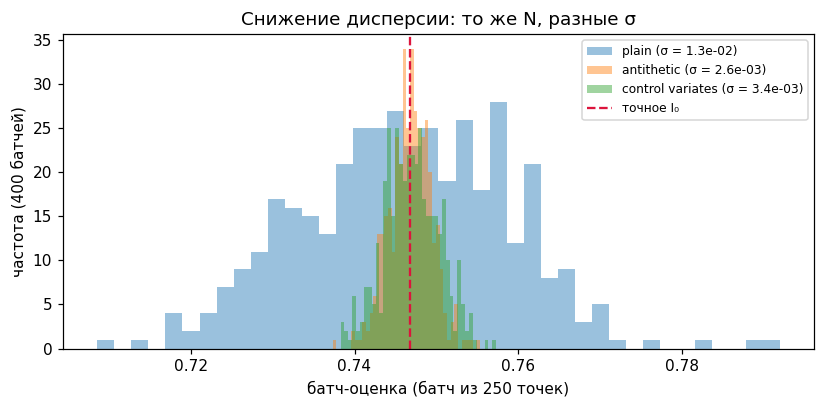

In [7]:
N = 100_000
u = rng.random(N)

# plain
fx = np.exp(-u * u)
var_plain = fx.var(ddof=1)

# (а) antithetic: пары u и 1-u
ua = rng.random(N // 2)
pair = (np.exp(-ua * ua) + np.exp(-(1 - ua) ** 2)) / 2
var_ant = pair.var(ddof=1)
rho = np.corrcoef(np.exp(-ua * ua), np.exp(-(1 - ua) ** 2))[0, 1]

# (б) control variates: g = e^{-x}, его интеграл 1 − e^{-1} известен
Eg = 1 - math.exp(-1)
gx = np.exp(-u)
c = np.cov(fx, gx, ddof=1)[0, 1] / gx.var(ddof=1)
cv = fx - c * (gx - Eg)
var_cv = cv.var(ddof=1)
rho_fg = np.corrcoef(fx, gx)[0, 1]

# (в) importance sampling: q(x) = e^{-x}/(1−e^{-1}), выборка по обратной ФР
uq = rng.random(N)
xq = -np.log(1 - uq * (1 - math.exp(-1)))
w = np.exp(-xq ** 2) * (1 - math.exp(-1)) / np.exp(-xq)   # f/q
var_is = w.var(ddof=1)
est_is = w.mean()

print(f'сравнение дисперсий на I0 = ∫₀¹ e^(-x²) dx, N = {N}:')
print(f'  plain:            var = {var_plain:.3e}')
print(f'  antithetic:       var = {var_ant:.3e}  (ρ = {rho:+.3f},'
      f' по формуле σ²(1+ρ)/2 = {var_plain * (1 + rho) / 2:.3e})')
print(f'  control variates: var = {var_cv:.3e}  (c* = {c:+.4f},'
      f' ρ_fg = {rho_fg:+.3f}, σ²(1−ρ²) = {var_plain * (1 - rho_fg ** 2):.3e})')
print(f'  importance s.:    var = {var_is:.3e}  (оценка {est_is:.9f},'
      f' ошибка {abs(est_is - I0):.2e})')
print(f'экономия по дисперсии (тот же N): '
      f'antithetic ×{var_plain / var_ant:.0f}, cv ×{var_plain / var_cv:.0f},'
      f' importance ×{var_plain / var_is:.0f}')

# визуализация: разброс батч-оценок (одинаковый размер батча у всех)
def batch_mean(draw, n, m=400):
    return np.array([draw(n).mean() for _ in range(m)])

n_b = 250
plain_batch = batch_mean(lambda k: np.exp(-rng.random(k) ** 2), n_b)

def ant_draw(k):
    uh = rng.random(k // 2)
    return (np.exp(-uh * uh) + np.exp(-(1 - uh) ** 2)) / 2

def cv_draw(k):
    uk = rng.random(k)
    return np.exp(-uk * uk) - c * (np.exp(-uk) - Eg)

ant_batch = batch_mean(ant_draw, n_b)
cv_batch = batch_mean(cv_draw, n_b)

fig, ax = plt.subplots(figsize=(7.6, 3.8))
ax.hist(plain_batch, bins=40, alpha=0.45,
        label=f'plain (σ = {plain_batch.std(ddof=1):.1e})')
ax.hist(ant_batch, bins=40, alpha=0.45,
        label=f'antithetic (σ = {ant_batch.std(ddof=1):.1e})')
ax.hist(cv_batch, bins=40, alpha=0.45,
        label=f'control variates (σ = {cv_batch.std(ddof=1):.1e})')
ax.axvline(I0, color='crimson', ls='--', lw=1.5, label='точное I₀')
ax.set_xlabel('батч-оценка (батч из 250 точек)')
ax.set_ylabel('частота (400 батчей)')
ax.legend(fontsize=8)
ax.set_title('Снижение дисперсии: то же N, разные σ')
plt.tight_layout(); plt.show()


In [8]:
N_budget = 1024
print(f'равный бюджет вычислений f: N = {N_budget}')
print(f"{'d':>3} | {'узлов куб.':>11} {'|I−T| кубатура':>15} | "
      f"{'|I_N−I| MC':>11} {'1.96·s/√N':>10} | {'победа':>11}")
for d in [1, 2, 4, 6, 8]:
    Iexact = I_of_d(d)
    # кубатура: Симпсон требует нечётного числа узлов по оси (n−1 чётных
    # отрезков); если Симпсон недостижим — midpoint на максимальном n
    n_full = int(math.floor(N_budget ** (1 / d)))
    n = n_full if n_full % 2 == 1 else n_full - 1
    if n >= 3:                            # Симпсон: n узлов, n−1 отрезков
        wv = simpson_weights(n - 1)
        xs = np.linspace(0, 1, n)
        val = (wv @ f0(xs)) ** d          # сепарабельная f
        nodes = n ** d
    elif n_full >= 2:                     # midpoint: n_full узлов по оси
        h = 1 / n_full
        xs = (np.arange(n_full) + 0.5) / n_full   # середины клеток
        val = (h * f0(xs).sum()) ** d
        nodes = n_full ** d
    else:                                 # fallback: центр куба
        val = f0(0.5) ** d
        nodes = 1
    err_cub = abs(val - Iexact)
    # Монте-Карло на полном бюджете
    pts = rng.random((N_budget, d))
    fvals = np.exp(-(pts ** 2).sum(axis=1))
    err_mc = abs(fvals.mean() - Iexact)
    sd = fvals.std(ddof=1)
    verdict = 'кубатура' if err_cub < err_mc else 'Монте-Карло'
    print(f'{d:3d} | {nodes:11d} {err_cub:15.2e} | {err_mc:11.2e} '
          f'{1.96 * sd / math.sqrt(N_budget):10.2e} | {verdict:>11}')
print('порог виден: при малых d кубатура несравнимо точнее, при d ≥ 6–8 '
      'Монте-Карло начинает выигрывать (наклоны −p/d против −1/2)')


равный бюджет вычислений f: N = 1024
  d |  узлов куб.  |I−T| кубатура |  |I_N−I| MC  1.96·s/√N |      победа
  1 |        1023        7.66e-15 |    1.63e-03   1.20e-02 |    кубатура
  2 |         961        1.51e-08 |    8.99e-03   1.34e-02 |    кубатура
  4 |         625        5.21e-05 |    2.63e-04   1.08e-02 |    кубатура
  6 |         729        4.97e-04 |    3.17e-03   7.11e-03 |    кубатура
  8 |         256        8.36e-03 |    2.53e-03   5.20e-03 | Монте-Карло
порог виден: при малых d кубатура несравнимо точнее, при d ≥ 6–8 Монте-Карло начинает выигрывать (наклоны −p/d против −1/2)
